In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt


In [2]:
W_covspectrum = pd.read_csv('../../resources/variants_definitions_sars/variant_signatures_covspectrum_2026_08_27.csv',
                                       header=0, index_col=0)
variants_covspectrum = W_covspectrum.columns


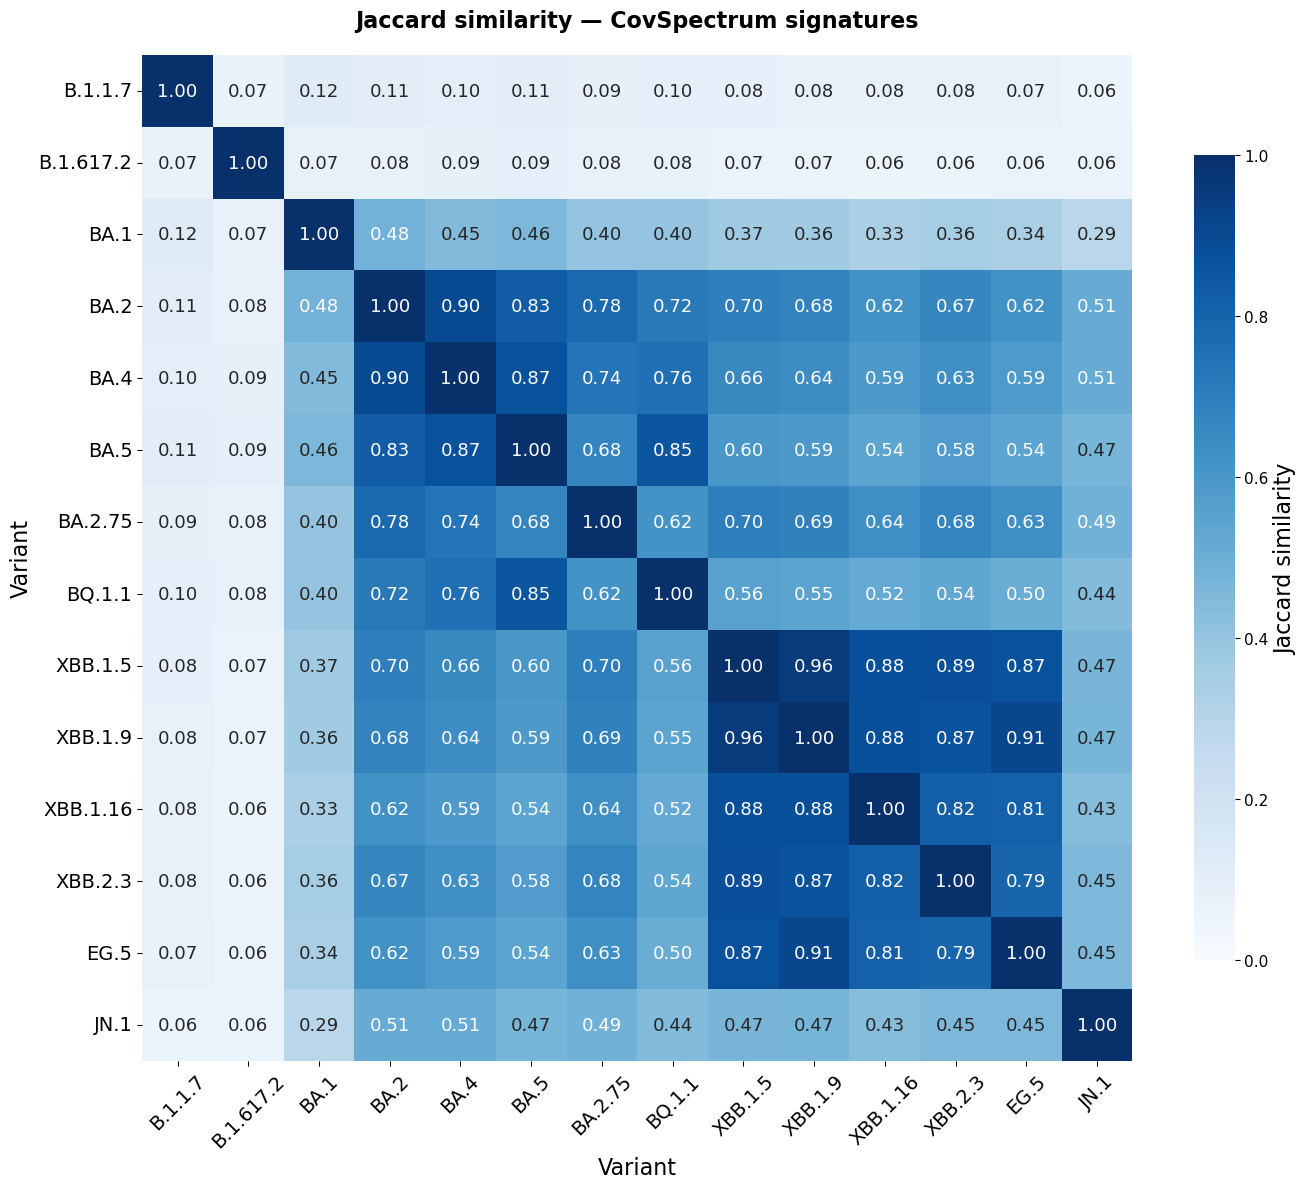


Most similar variant pairs (Jaccard > 0.7):
  BA.2         — BA.4          Jaccard=0.901
  BA.2         — BA.5          Jaccard=0.831
  BA.2         — BA.2.75       Jaccard=0.783
  BA.2         — BQ.1.1        Jaccard=0.720
  BA.4         — BA.5          Jaccard=0.873
  BA.4         — BA.2.75       Jaccard=0.736
  BA.4         — BQ.1.1        Jaccard=0.756
  BA.5         — BQ.1.1        Jaccard=0.853
  BA.2.75      — XBB.1.5       Jaccard=0.703
  XBB.1.5      — XBB.1.9       Jaccard=0.957
  XBB.1.5      — XBB.1.16      Jaccard=0.880
  XBB.1.5      — XBB.2.3       Jaccard=0.885
  XBB.1.5      — EG.5          Jaccard=0.873
  XBB.1.9      — XBB.1.16      Jaccard=0.881
  XBB.1.9      — XBB.2.3       Jaccard=0.867
  XBB.1.9      — EG.5          Jaccard=0.911
  XBB.1.16     — XBB.2.3       Jaccard=0.817
  XBB.1.16     — EG.5          Jaccard=0.809
  XBB.2.3      — EG.5          Jaccard=0.794


In [3]:
from scipy.spatial.distance import cdist
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# ── Jaccard similarity — covspectrum vs covspectrum ───────────────────────────
dist_matrix = cdist(
    W_covspectrum.values.T,
    W_covspectrum.values.T,
    metric='jaccard')

sim_matrix = 1 - dist_matrix

sim_df = pd.DataFrame(
    sim_matrix,
    index=W_covspectrum.columns,
    columns=W_covspectrum.columns)

# ── Plot ──────────────────────────────────────────────────────────────────────
n = len(W_covspectrum.columns)
fig, ax = plt.subplots(figsize=(14,12))

sns.heatmap(sim_df,
            ax=ax,
            cmap='Blues',
            vmin=0, vmax=1,
            annot=True, fmt='.2f',
            annot_kws={'size': 13},  # ← Cell values
            cbar_kws={'label': 'Jaccard similarity', 'shrink': 0.8})

ax.set_title('Jaccard similarity — CovSpectrum signatures', 
             fontsize=16, fontweight='bold', pad=20)
ax.set_xlabel('Variant', fontsize=16)
ax.set_ylabel('Variant', fontsize=16)

# Tick labels
ax.tick_params(axis='x', rotation=45, labelsize=14)
ax.tick_params(axis='y', rotation=0, labelsize=14)

# Colorbar label
cbar = ax.collections[0].colorbar
cbar.ax.tick_params(labelsize=11)
cbar.set_label('Jaccard similarity', fontsize=16)

plt.tight_layout()
plt.savefig('W_covspectrum_signatures.pdf', dpi=150, bbox_inches='tight')
plt.show()

# ── Most similar pairs (excluding diagonal) ───────────────────────────────────
print("\nMost similar variant pairs (Jaccard > 0.7):")
for i in range(n):
    for j in range(i+1, n):
        s = sim_matrix[i, j]
        if s > 0.7:
            print(f"  {W_covspectrum.columns[i]:<12} — "
                  f"{W_covspectrum.columns[j]:<12}  Jaccard={s:.3f}")


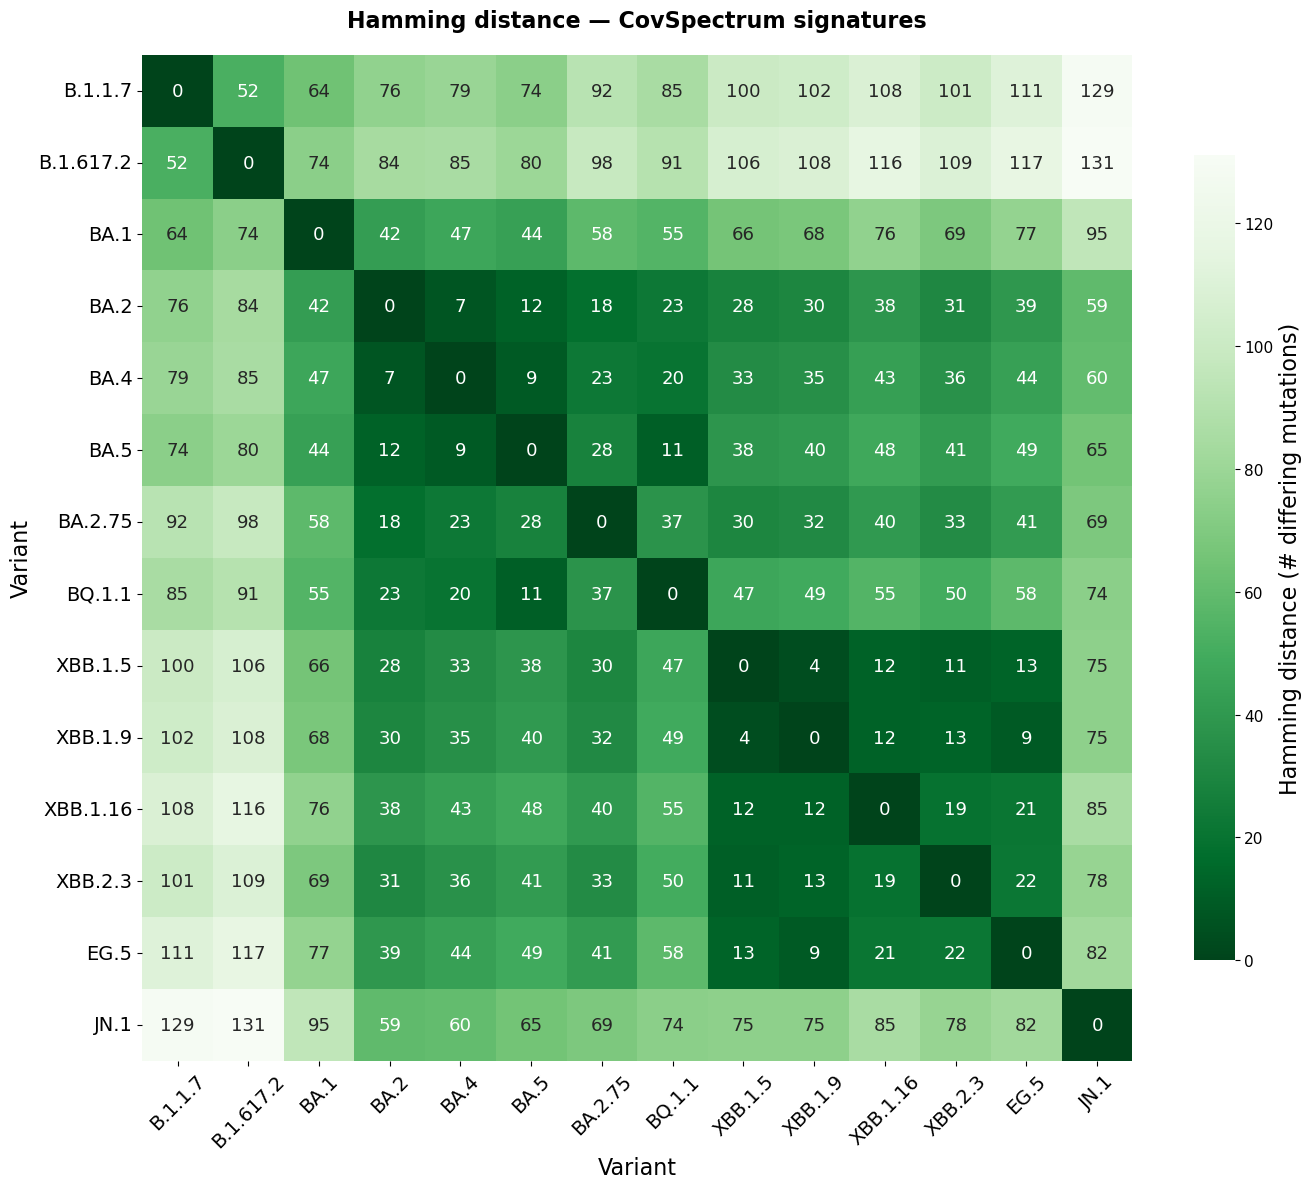


Most similar variant pairs (< 10 differing mutations):
  BA.2         — BA.4          Hamming=7
  BA.4         — BA.5          Hamming=9
  XBB.1.5      — XBB.1.9       Hamming=4
  XBB.1.9      — EG.5          Hamming=9


In [4]:
from scipy.spatial.distance import cdist
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# ── Hamming distance (raw count) — covspectrum vs covspectrum ────────────────
n_mutations = W_covspectrum.shape[0]

dist_matrix_hamming = cdist(
    W_covspectrum.values.T,
    W_covspectrum.values.T,
    metric='hamming') * n_mutations

dist_df_hamming = pd.DataFrame(
    dist_matrix_hamming,
    index=W_covspectrum.columns,
    columns=W_covspectrum.columns)

# ── Plot ──────────────────────────────────────────────────────────────────────
n = len(W_covspectrum.columns)
fig, ax = plt.subplots(figsize=(14, 12))

sns.heatmap(dist_df_hamming,
            ax=ax,
            cmap='Greens_r',
            vmin=0, vmax=dist_matrix_hamming.max(),
            annot=True, fmt='.0f',
            annot_kws={'size': 13},
            cbar_kws={'label': 'Hamming distance (# differing mutations)', 'shrink': 0.8})

ax.set_title('Hamming distance — CovSpectrum signatures',
             fontsize=16, fontweight='bold', pad=20)
ax.set_xlabel('Variant', fontsize=16)
ax.set_ylabel('Variant', fontsize=16)

ax.tick_params(axis='x', rotation=45, labelsize=14)
ax.tick_params(axis='y', rotation=0, labelsize=14)

cbar = ax.collections[0].colorbar
cbar.ax.tick_params(labelsize=11)
cbar.set_label('Hamming distance (# differing mutations)', fontsize=16)

plt.tight_layout()
plt.savefig('W_covspectrum_hamming.pdf', dpi=150, bbox_inches='tight')
plt.show()

# ── Most similar pairs (excluding diagonal), i.e. fewest differing mutations ─
print("\nMost similar variant pairs (< 10 differing mutations):")
for i in range(n):
    for j in range(i + 1, n):
        d = dist_matrix_hamming[i, j]
        if d < 10:
            print(f"  {W_covspectrum.columns[i]:<12} — "
                  f"{W_covspectrum.columns[j]:<12}  Hamming={d:.0f}")